# IDXBUMN20 Portfolio Optimization

Proyek ini membangun optimasi portofolio menggunakan Modern Portfolio Theory (Markowitz) pada 20 saham konstituen IDXBUMN20, yaitu saham-saham BUMN, BUMD, dan afiliasinya yang tercatat di Bursa Efek Indonesia.

Tahapan yang dilakukan:
1. **Data collection & cleaning** — download harga historis 20 saham IDXBUMN20
2. **Return, risk & correlation analysis** — hitung return tahunan, volatilitas, dan korelasi antar saham
3. **Monte Carlo simulation** — simulasi 10.000 portofolio random untuk membentuk Efficient Frontier
4. **Mathematical optimization** — cari alokasi optimal (Max Sharpe Ratio & Min Variance) menggunakan `scipy.optimize`
5. **Perbandingan strategi** — Max Sharpe vs Min Variance vs Equal Weight (baseline)
6. **Visualisasi** — scatter plot Efficient Frontier dan correlation heatmap

Output akhir adalah rekomendasi alokasi bobot portofolio optimal dari 20 saham IDXBUMN20.

## 1. Setup & Data Collection

Import library yang dibutuhkan dan definisikan daftar 20 ticker saham konstituen IDXBUMN20.

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Daftar 20 ticker konstituen IDXBUMN20
idxbumn20_tickers = [
    'BBRI.JK', 'BMRI.JK', 'TLKM.JK', 'ANTM.JK', 'PGAS.JK',
    'PTBA.JK', 'BBNI.JK', 'ADHI.JK', 'SMGR.JK', 'JSMR.JK',
    'BRIS.JK', 'PTPP.JK', 'BBTN.JK', 'ELSA.JK', 'PGEO.JK',
    'BJTM.JK', 'AGRO.JK', 'BJBR.JK', 'SMBR.JK', 'MTEL.JK'
]

print(f"Jumlah saham: {len(idxbumn20_tickers)}")

Jumlah saham: 20


## 2. Data Download & Cleaning

Download data harga historis (2 tahun terakhir) untuk 20 saham IDXBUMN20. Setelah itu, cek kualitas data (missing values) dan bersihkan sebelum dipakai untuk perhitungan metrik.

In [2]:
start_date = "2024-08-22"
end_date = "2026-08-22"

raw_data = yf.download(idxbumn20_tickers, start=start_date, end=end_date,
                        group_by='ticker', progress=False)

close_prices = pd.DataFrame({ticker: raw_data[ticker]['Close'] for ticker in idxbumn20_tickers})

print(f"Periode data: {close_prices.index.min().date()} s/d {close_prices.index.max().date()}")
print(f"Shape close_prices: {close_prices.shape}")
close_prices.head()

Periode data: 2024-08-22 s/d 2026-08-21
Shape close_prices: (479, 20)


,BBRI.JK,BMRI.JK,TLKM.JK,ANTM.JK,PGAS.JK,PTBA.JK,BBNI.JK,ADHI.JK,SMGR.JK,JSMR.JK,BRIS.JK,PTPP.JK,BBTN.JK,ELSA.JK,PGEO.JK,BJTM.JK,AGRO.JK,BJBR.JK,SMBR.JK,MTEL.JK
Date,,,,,,,,,,,,,,,,,,,,
2024-08-22,"4,181.7007","5,767.5356","2,502.7271","1,278.1823","1,365.0138","2,305.9475","4,456.0029",286.0000,"3,802.4319","4,999.0537","2,553.2229",424.0000,"1,242.2933",410.1673,"1,090.4226",451.8922,254.0000,819.5708,244.1984,604.2526
2024-08-23,"4,264.5063","5,767.5356","2,528.4399","1,287.0585","1,415.2598","2,339.8586","4,603.8325",298.0000,"3,840.4563","4,930.5737","2,631.1838",442.0000,"1,289.3500",411.8763,"1,076.6777",460.0344,284.0000,823.6893,244.1984,613.3391
2024-08-26,"4,388.7153","5,767.5356","2,554.1531","1,313.6873","1,406.8854","2,348.3362","4,667.1885",308.0000,"3,811.9380","4,953.3999","2,660.4192",456.0000,"1,350.5234",420.4215,"1,085.8409",468.1765,280.0000,827.8077,248.0745,613.3391
2024-08-27,"4,285.2075","5,747.0835","2,562.7239","1,304.8110","1,323.1422","2,356.8140","4,561.5962",300.0000,"3,773.9138","4,953.3999","2,670.1646",442.0000,"1,317.5839",417.0034,"1,081.2594",464.1054,274.0000,827.8077,244.1984,608.7958
2024-08-28,"4,264.5063","5,910.7012","2,554.1531","1,287.0585","1,318.9551","2,356.8140","4,540.4775",296.0000,"3,821.4441","4,953.3999","2,660.4192",434.0000,"1,336.4065",411.8763,"1,058.3514",468.1765,274.0000,823.6893,259.7030,613.3391


In [3]:
# Cek missing value per saham
missing_pct = close_prices.isna().mean().sort_values(ascending=False) * 100
print("Persentase missing value per saham:")
print(missing_pct[missing_pct > 0] if (missing_pct > 0).any() else "Tidak ada missing value.")

# Forward fill untuk gap kecil (hari libur bursa berbeda antar saham),
# lalu drop baris yang masih NaN di awal periode (saham yang listing belakangan)
close_prices = close_prices.ffill().dropna()
print(f"\nShape setelah cleaning: {close_prices.shape}")

Persentase missing value per saham:
BBRI.JK   0.2088
BMRI.JK   0.2088
SMBR.JK   0.2088
BJBR.JK   0.2088
AGRO.JK   0.2088
BJTM.JK   0.2088
PGEO.JK   0.2088
ELSA.JK   0.2088
BBTN.JK   0.2088
PTPP.JK   0.2088
BRIS.JK   0.2088
JSMR.JK   0.2088
SMGR.JK   0.2088
BBNI.JK   0.2088
PTBA.JK   0.2088
PGAS.JK   0.2088
ANTM.JK   0.2088
TLKM.JK   0.2088
MTEL.JK   0.2088
dtype: float64

Shape setelah cleaning: (479, 20)


## 3. Return, Risk & Correlation Analysis

Hitung daily return, lalu turunkan return tahunan, volatilitas tahunan, dan Sharpe Ratio per saham. Bagian ini juga menghitung correlation matrix antar saham sebagai dasar untuk melihat potensi diversifikasi.

In [4]:
TRADING_DAYS = 252
RISK_FREE_RATE = 0.06  # asumsi risk-free rate tahunan (SBN ~6%)

daily_returns = close_prices.pct_change().dropna()

annual_returns = daily_returns.mean() * TRADING_DAYS
annual_volatility = daily_returns.std() * np.sqrt(TRADING_DAYS)

risk_return_df = pd.DataFrame({
    'Annual Return': annual_returns,
    'Annual Volatility': annual_volatility,
    'Sharpe Ratio': (annual_returns - RISK_FREE_RATE) / annual_volatility
}).sort_values('Sharpe Ratio', ascending=False)

risk_return_df

,Annual Return,Annual Volatility,Sharpe Ratio
ANTM.JK,0.6238,0.5385,1.0470
ELSA.JK,0.3872,0.4402,0.7431
BJTM.JK,0.0929,0.1945,0.1693
PGAS.JK,0.1121,0.3317,0.1571
TLKM.JK,0.1018,0.3990,0.1047
PGEO.JK,0.0955,0.4707,0.0754
BBTN.JK,0.0831,0.4281,0.0540
PTBA.JK,0.0590,0.2768,-0.0037
SMBR.JK,-0.0415,0.5567,-0.1823
BBNI.JK,-0.0294,0.3603,-0.2482


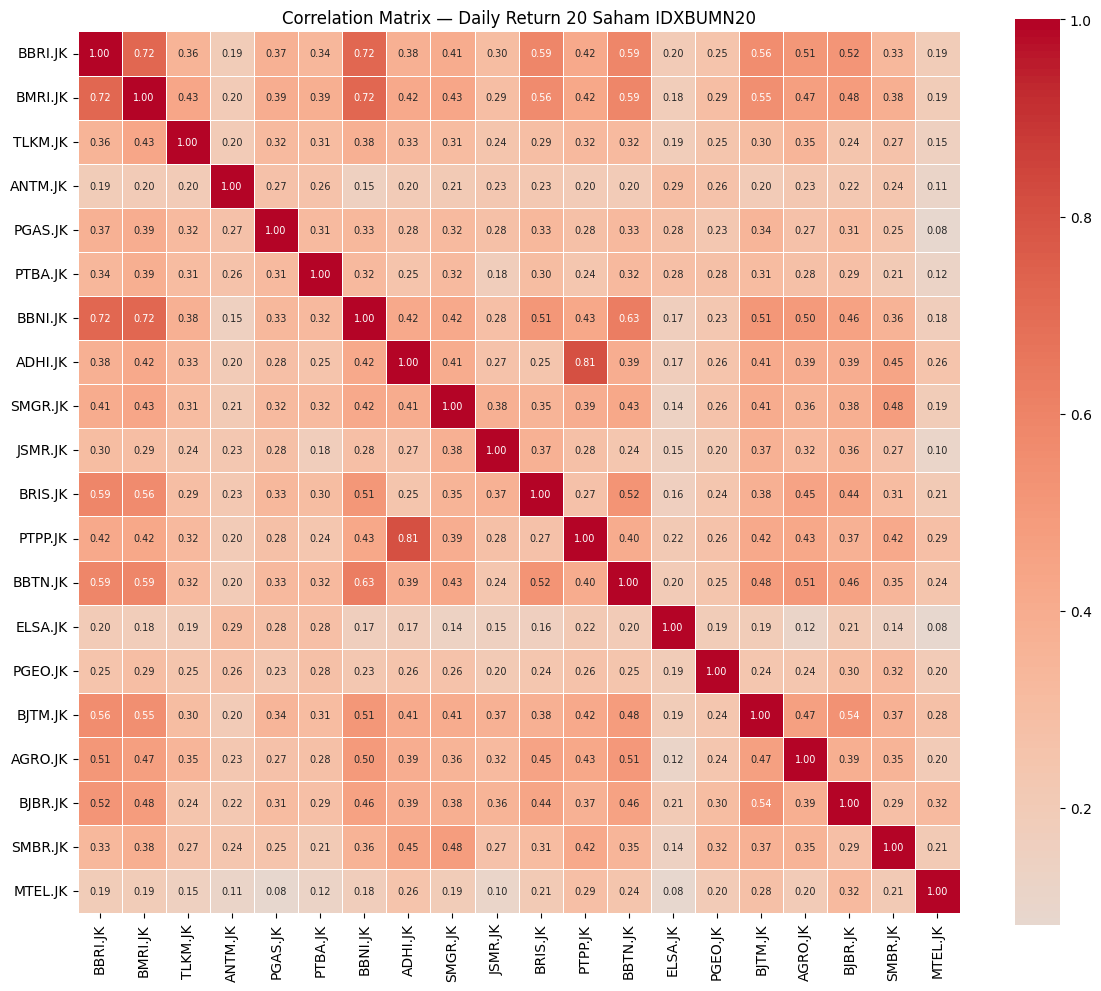

In [5]:
corr_matrix = daily_returns.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, annot_kws={"size": 7})
plt.title('Correlation Matrix — Daily Return 20 Saham IDXBUMN20')
plt.tight_layout()
plt.show()

## 4. Monte Carlo Simulation — Efficient Frontier

Simulasikan 10.000 kombinasi bobot portofolio random dari 20 saham, lalu hitung expected return, volatility, dan Sharpe ratio masing-masing. Titik-titik hasil simulasi ini membentuk Efficient Frontier secara visual.

In [6]:
mean_returns = daily_returns.mean() * TRADING_DAYS
cov_matrix = daily_returns.cov() * TRADING_DAYS
n_assets = len(idxbumn20_tickers)

N_PORTFOLIOS = 10000
np.random.seed(42)

results = np.zeros((3, N_PORTFOLIOS))
weights_record = []

for i in range(N_PORTFOLIOS):
    weights = np.random.random(n_assets)
    weights /= np.sum(weights)
    weights_record.append(weights)

    port_return = np.dot(weights, mean_returns)
    port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    sharpe = (port_return - RISK_FREE_RATE) / port_vol

    results[0, i] = port_return
    results[1, i] = port_vol
    results[2, i] = sharpe

simulated_df = pd.DataFrame({
    'Return': results[0],
    'Volatility': results[1],
    'Sharpe': results[2]
})

sim_max_sharpe_idx = simulated_df['Sharpe'].idxmax()
sim_min_vol_idx = simulated_df['Volatility'].idxmin()

print("Hasil simulasi 10.000 portofolio random:")
print(f"  Best Sharpe   : Return={simulated_df.loc[sim_max_sharpe_idx, 'Return']:.2%}, "
      f"Vol={simulated_df.loc[sim_max_sharpe_idx, 'Volatility']:.2%}, "
      f"Sharpe={simulated_df.loc[sim_max_sharpe_idx, 'Sharpe']:.3f}")
print(f"  Lowest Vol    : Return={simulated_df.loc[sim_min_vol_idx, 'Return']:.2%}, "
      f"Vol={simulated_df.loc[sim_min_vol_idx, 'Volatility']:.2%}, "
      f"Sharpe={simulated_df.loc[sim_min_vol_idx, 'Sharpe']:.3f}")

Hasil simulasi 10.000 portofolio random:
  Best Sharpe   : Return=10.41%, Vol=22.67%, Sharpe=0.195
  Lowest Vol    : Return=0.43%, Vol=20.44%, Sharpe=-0.273


## 5. Mathematical Optimization — Max Sharpe & Min Variance

Simulasi random di atas hanya memberi estimasi kasar. Bagian ini mencari alokasi optimal secara matematis menggunakan `scipy.optimize.minimize` (Sequential Least Squares Programming) untuk dua target:
- **Max Sharpe Ratio Portfolio** — portofolio dengan rasio return-terhadap-risiko terbaik
- **Min Variance Portfolio** — portofolio dengan risiko (volatilitas) terendah

Sebagai pembanding, turut dihitung **Equal Weight Portfolio** (bobot sama rata 5% per saham) sebagai baseline naif.

In [7]:
def portfolio_performance(weights, mean_returns, cov_matrix):
    port_return = np.dot(weights, mean_returns)
    port_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return port_return, port_vol

def neg_sharpe(weights, mean_returns, cov_matrix, rf):
    p_ret, p_vol = portfolio_performance(weights, mean_returns, cov_matrix)
    return -(p_ret - rf) / p_vol

def portfolio_vol(weights, mean_returns, cov_matrix):
    return portfolio_performance(weights, mean_returns, cov_matrix)[1]

constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})  # total bobot = 100%
bounds = tuple((0, 1) for _ in range(n_assets))                 # no short selling
initial_guess = n_assets * [1. / n_assets]

# Max Sharpe Ratio Portfolio
opt_sharpe = minimize(neg_sharpe, initial_guess, args=(mean_returns, cov_matrix, RISK_FREE_RATE),
                       method='SLSQP', bounds=bounds, constraints=constraints)
weights_max_sharpe = opt_sharpe.x

# Min Variance Portfolio
opt_minvol = minimize(portfolio_vol, initial_guess, args=(mean_returns, cov_matrix),
                       method='SLSQP', bounds=bounds, constraints=constraints)
weights_min_vol = opt_minvol.x

# Equal Weight Portfolio (baseline)
weights_equal = np.array(n_assets * [1. / n_assets])

allocation_df = pd.DataFrame({
    'Ticker': [t.replace('.JK', '') for t in idxbumn20_tickers],
    'Max Sharpe (%)': weights_max_sharpe * 100,
    'Min Variance (%)': weights_min_vol * 100,
    'Equal Weight (%)': weights_equal * 100
}).set_index('Ticker').sort_values('Max Sharpe (%)', ascending=False)

allocation_df

,Max Sharpe (%),Min Variance (%),Equal Weight (%)
Ticker,,,
ANTM,60.8488,0.0000,5.0000
ELSA,39.1512,3.2854,5.0000
PTBA,0.0000,15.6300,5.0000
SMGR,0.0000,0.0000,5.0000
BBRI,0.0000,0.0000,5.0000
AGRO,0.0000,0.0000,5.0000
TLKM,0.0000,0.4820,5.0000
PGAS,0.0000,4.3204,5.0000
BBTN,0.0000,0.0000,5.0000


## 6. Perbandingan Strategi & Visualisasi Efficient Frontier

Bandingkan performa (expected return, volatility, Sharpe ratio) dari ketiga strategi alokasi, lalu plot posisinya di atas Efficient Frontier hasil simulasi Monte Carlo.

In [8]:
strategies = {
    'Max Sharpe': weights_max_sharpe,
    'Min Variance': weights_min_vol,
    'Equal Weight': weights_equal
}

comparison_results = []
for name, w in strategies.items():
    ret, vol = portfolio_performance(w, mean_returns, cov_matrix)
    sharpe = (ret - RISK_FREE_RATE) / vol
    comparison_results.append({
        'Strategi': name,
        'Expected Return': ret,
        'Volatility': vol,
        'Sharpe Ratio': sharpe
    })

comparison_df = pd.DataFrame(comparison_results).set_index('Strategi')
comparison_df

,Expected Return,Volatility,Sharpe Ratio
Strategi,,,
Max Sharpe,0.5312,0.4125,1.1423
Min Variance,0.0303,0.1632,-0.1820
Equal Weight,-0.0082,0.2386,-0.2860


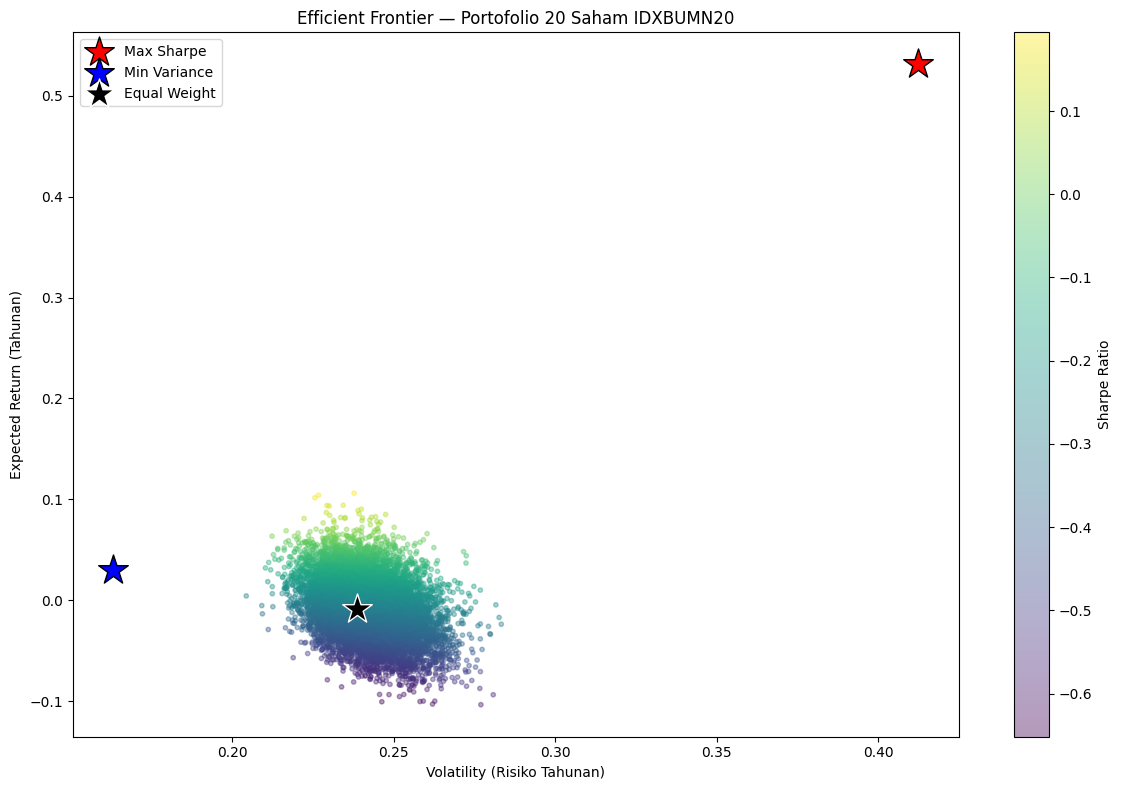

In [9]:
ret_max_sharpe, vol_max_sharpe = portfolio_performance(weights_max_sharpe, mean_returns, cov_matrix)
ret_min_vol, vol_min_vol = portfolio_performance(weights_min_vol, mean_returns, cov_matrix)
ret_equal, vol_equal = portfolio_performance(weights_equal, mean_returns, cov_matrix)

plt.figure(figsize=(12, 8))
sc = plt.scatter(simulated_df['Volatility'], simulated_df['Return'],
                  c=simulated_df['Sharpe'], cmap='viridis', alpha=0.4, s=10)
plt.colorbar(sc, label='Sharpe Ratio')

plt.scatter(vol_max_sharpe, ret_max_sharpe, marker='*', color='red', s=500,
            edgecolors='black', label='Max Sharpe', zorder=5)
plt.scatter(vol_min_vol, ret_min_vol, marker='*', color='blue', s=500,
            edgecolors='black', label='Min Variance', zorder=5)
plt.scatter(vol_equal, ret_equal, marker='*', color='black', s=500,
            edgecolors='white', label='Equal Weight', zorder=5)

plt.xlabel('Volatility (Risiko Tahunan)')
plt.ylabel('Expected Return (Tahunan)')
plt.title('Efficient Frontier — Portofolio 20 Saham IDXBUMN20')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Insight & Kesimpulan

### Ringkasan Hasil
- **Max Sharpe Portfolio** terkonsentrasi hanya pada 2 saham: ANTM (60,85%) dan ELSA (39,15%) — expected return 53,12%, volatility 41,25%, Sharpe ratio 1,142
- **Min Variance Portfolio** lebih terdiversifikasi ke 8 saham: BJTM (37,82%), BJBR (18,80%), PTBA (15,63%), MTEL (12,48%), JSMR (7,18%), PGAS (4,32%), ELSA (3,29%), TLKM (0,48%) — expected return 3,03%, volatility 16,32% (terendah di antara ketiga strategi), Sharpe ratio -0,182
- **Equal Weight** sebagai baseline menghasilkan return -0,82%, volatility 23,86%, Sharpe ratio -0,286 — return dan Sharpe ratio-nya terendah dari ketiga strategi, meski volatility-nya masih lebih rendah dibanding Max Sharpe

### Insight Diversifikasi
- Dari correlation heatmap, saham-saham perbankan BUMN (BBNI, BBRI, BMRI, BRIS, BJBR, BJTM, AGRO) kemungkinan berkorelasi tinggi satu sama lain
- ANTM dan ELSA (sektor tambang/energi) mendominasi Max Sharpe Portfolio karena Sharpe ratio individual tertinggi (1,047 dan 0,743) — jauh di atas 18 saham lain yang mayoritas justru negatif
- Min Variance Portfolio secara alami memilih saham lintas sektor (perbankan: BJTM, BJBR; tambang/energi: PTBA, ELSA, PGAS; telekomunikasi: MTEL, TLKM; konstruksi: JSMR) — konsisten dengan prinsip diversifikasi Markowitz, di mana korelasi rendah antar sektor membantu menekan volatilitas portofolio
- Baik Min Variance maupun Equal Weight menghasilkan Sharpe ratio negatif, artinya secara historis kedua portofolio ini underperform risk-free rate — mengindikasikan bahwa mayoritas saham IDXBUMN20 (di luar ANTM & ELSA) mengalami tekanan return selama periode 2 tahun ini, bukan sekadar soal bobot alokasi
- Monte Carlo simulation (10.000 portofolio random) hanya menemukan Sharpe terbaik 0,195 — jauh di bawah hasil optimasi matematis (1,142). Ini menunjukkan random sampling di ruang 20 dimensi hampir tidak pernah menemukan solusi ekstrem (corner solution) seperti alokasi 2-saham ini; optimasi `scipy` diperlukan untuk menemukan titik optimal sebenarnya

### Limitasi
- **Backward-looking**: optimasi menggunakan data historis 2 tahun, tidak menjamin performa yang sama ke depan
- **Asumsi normalitas return**: model Markowitz mengasumsikan return berdistribusi normal
- **Konsentrasi berlebihan**: Max Sharpe Portfolio hanya terdiri dari 2 dari 20 saham — secara praktik ini berisiko tinggi meski Sharpe ratio-nya matematis optimal; perlu constraint bobot maksimum per saham untuk portofolio yang lebih realistis
- **Risk-free rate merupakan asumsi tetap** (6% per tahun, acuan imbal hasil SBN)
- **Belum memasukkan biaya transaksi & pajak**